In [2]:
import pandas as pd # Data analysis ( pd and np )
import numpy as np # Data visualization ( matplotlib and sns )
import matplotlib.pyplot as plt # Working in Google Colab ( to upload file from local system )
import seaborn as sns # Clean & readable numeric output.
pd.set_option('display.float_format', lambda x: '%.3f' % x) # This line controls how decimal numbers are displayed in Pandas.show only 3 decimal places
from google.colab import files
%matplotlib inline

The above codes imports essential Python libraries for data analysis and visualization, sets decimal display formatting in Pandas, and enables file upload functionality in Google Colab.

In [3]:
uploaded = files.upload() # To upload file from local system

Saving austo_automobile .csv to austo_automobile .csv


In [4]:
df = pd.read_csv('austo_automobile .csv') # reads csv file into dataframe which is assigned to the variable df

In [5]:
print("There are",df.shape[0],"rows and",df.shape[1],"columns") # Tells No:of rows and columns

There are 1581 rows and 14 columns


In [6]:
print ("The list of columns names are",df.columns) #Lists all column names
df.info() # Column names,Data types (int, float, object, etc.),Non-null counts (helps spot missing values)

The list of columns names are Index(['Age', 'Gender', 'Profession', 'Marital_status', 'Education',
       'No_of_Dependents', 'Personal_loan', 'House_loan', 'Partner_working',
       'Salary', 'Partner_salary', 'Total_salary', 'Price', 'Make'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1581 entries, 0 to 1580
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Age               1581 non-null   int64  
 1   Gender            1528 non-null   object 
 2   Profession        1581 non-null   object 
 3   Marital_status    1581 non-null   object 
 4   Education         1581 non-null   object 
 5   No_of_Dependents  1581 non-null   int64  
 6   Personal_loan     1581 non-null   object 
 7   House_loan        1581 non-null   object 
 8   Partner_working   1581 non-null   object 
 9   Salary            1581 non-null   int64  
 10  Partner_salary    1475 non-null   float64
 11  Total_sala

In [7]:
df.dtypes #shows data type of each column

,0
Age,int64
Gender,object
Profession,object
Marital_status,object
Education,object
No_of_Dependents,int64
Personal_loan,object
House_loan,object
Partner_working,object
Salary,int64


In [8]:
df.isnull().sum() #shows the number of missing values in each column

,0
Age,0
Gender,53
Profession,0
Marital_status,0
Education,0
No_of_Dependents,0
Personal_loan,0
House_loan,0
Partner_working,0
Salary,0


In [9]:
df.loc[df['Gender'].isnull()==True] #The code uses isnull() to identify missing values in the specified columns of the DataFrame. Then, any(axis=1) checks each row to see if at least one value is missing, and the DataFrame is filtered to return only those rows.

,Age,Gender,Profession,Marital_status,Education,No_of_Dependents,Personal_loan,House_loan,Partner_working,Salary,Partner_salary,Total_salary,Price,Make
24,46,NaN,Business,Married,Post Graduate,3,Yes,No,Yes,78000,600.000,78600,50000,SUV
25,46,NaN,Salaried,Married,Post Graduate,3,No,No,Yes,87900,700.000,88600,50000,SUV
67,53,NaN,Salaried,Married,Graduate,4,Yes,No,Yes,80900,30000.000,110900,49000,SUV
125,47,NaN,Salaried,Single,Post Graduate,2,Yes,No,No,87200,0.000,87200,49000,SUV
203,44,NaN,Salaried,Single,Post Graduate,0,Yes,No,No,68600,0.000,68600,50000,SUV
302,41,NaN,Salaried,Married,Graduate,1,Yes,No,No,55900,0.000,55900,32000,Sedan
325,40,NaN,Business,Married,Graduate,1,No,Yes,No,59600,0.000,59600,31000,Sedan
463,36,NaN,Salaried,Married,Post Graduate,3,Yes,No,No,66600,0.000,66600,49000,SUV
485,35,NaN,Business,Married,Post Graduate,2,Yes,Yes,Yes,61600,25000.000,86600,31000,Sedan
528,34,NaN,Salaried,Single,Post Graduate,2,No,Yes,No,64800,0.000,64800,32000,Sedan


In [10]:
df.loc[df['Partner_salary'].isnull()==True]

,Age,Gender,Profession,Marital_status,Education,No_of_Dependents,Personal_loan,House_loan,Partner_working,Salary,Partner_salary,Total_salary,Price,Make
40,53,Female,Salaried,Married,Graduate,1,Yes,No,No,72100,NaN,72100,60000,SUV
43,52,Male,Salaried,Married,Post Graduate,3,No,No,Yes,87600,NaN,88200,51000,SUV
49,52,Female,Business,Married,Post Graduate,4,No,No,Yes,90300,NaN,170400,69000,SUV
59,54,Male,Salaried,Married,Graduate,3,Yes,No,Yes,80600,NaN,81000,51000,SUV
111,48,Female,Business,Married,Graduate,3,No,No,Yes,90300,NaN,161100,62000,SUV
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1559,22,Male,Business,Married,Post Graduate,3,Yes,No,No,52100,NaN,52100,28000,Hatchback
1567,22,Male,Salaried,Single,Graduate,0,Yes,Yes,No,39700,NaN,39700,23000,Hatchback
1568,22,Male,Salaried,Married,Graduate,3,No,Yes,No,38000,NaN,38000,23000,Sedan
1577,22,Male,Business,Married,Graduate,4,No,No,No,32000,NaN,32000,31000,Hatchback


In [11]:
df['Total_salary'].isnull().sum()

np.int64(0)

In [12]:
df['Partner_salary'] = df['Partner_salary'].fillna(df['Partner_salary'].median()) # To treat missing values with median for numerical variable

In [13]:
df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0]) #* Gender is a categorical variable, so measures like mean or median are not applicable.

In [14]:
df.loc[df['Partner_salary'].isnull(),'Partner_salary'] = (df['Total_salary'] - df['Salary'])
 # Numerical variable Partner_salary was imputed using median to reduce the impact of outliers.

In [15]:
df.isnull().sum() # Verifying once again after treating the missing values

,0
Age,0
Gender,0
Profession,0
Marital_status,0
Education,0
No_of_Dependents,0
Personal_loan,0
House_loan,0
Partner_working,0
Salary,0


In [16]:
df['Make'].unique()

array(['SUV', 'Sedan', 'Hatchback'], dtype=object)

In [17]:
df.describe()

,Age,No_of_Dependents,Salary,Partner_salary,Total_salary,Price
count,1581.000,1581.000,1581.000,1581.000,1581.000,1581.000
mean,31.922,2.458,60392.220,20585.895,79625.996,35597.723
std,8.426,0.943,14674.825,18952.939,25545.858,13633.637
min,22.000,0.000,30000.000,0.000,30000.000,18000.000
25%,25.000,2.000,51900.000,0.000,60500.000,25000.000
50%,29.000,2.000,59500.000,25600.000,78000.000,31000.000
75%,38.000,3.000,71800.000,38000.000,95900.000,47000.000
max,54.000,4.000,99300.000,80500.000,171000.000,70000.000


In [18]:
df.duplicated().sum() # if a duplicate check using df.duplicated().sum() returned zero, it confirms that the dataset contains unique observations

np.int64(0)

In [19]:
df['Price'].agg(['mean', 'median', 'std']) #calculates descriptive statistics—mean, median, and standard deviation—for the 'Price' column

,Price
mean,35597.723
median,31000.000
std,13633.637


In [20]:
df[df['Age'] <= 0]  #Below code use Boolean indexing to identify whether age,salary,dependents,or price containing negative values or zero's
df[df['Salary'] < 0]
df[df['No_of_Dependents'] < 0]
df[df['Price'] < 0]

,Age,Gender,Profession,Marital_status,Education,No_of_Dependents,Personal_loan,House_loan,Partner_working,Salary,Partner_salary,Total_salary,Price,Make


In [21]:
df['Gender'].value_counts() #Inspecting Gender column for misspelled words before correcting

,count
Gender,
Male,1252
Female,327
Femal,1
Femle,1


In [22]:
df['Gender'] = df['Gender'].replace({'Femal':'Female','Femle':'Female'}) #Misspelled words being corrected with the replace() function

###### Below code eliminates unnecessary spaces at the start and finish of each value and changes text to title case and returns the cleaned values to the Gender column.

In [23]:
df['Gender'] = df['Gender'].str.strip().str.title()

In [24]:
df['Gender'].value_counts()

,count
Gender,
Male,1252
Female,329


In [25]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1581.000,NaN,NaN,NaN,31.922,8.426,22.000,25.000,29.000,38.000,54.000
Gender,1581,2,Male,1252,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Profession,1581,2,Salaried,896,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Marital_status,1581,2,Married,1443,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education,1581,2,Post Graduate,985,NaN,NaN,NaN,NaN,NaN,NaN,NaN
No_of_Dependents,1581.000,NaN,NaN,NaN,2.458,0.943,0.000,2.000,2.000,3.000,4.000
Personal_loan,1581,2,Yes,792,NaN,NaN,NaN,NaN,NaN,NaN,NaN
House_loan,1581,2,No,1054,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Partner_working,1581,2,Yes,868,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Salary,1581.000,NaN,NaN,NaN,60392.220,14674.825,30000.000,51900.000,59500.000,71800.000,99300.000


######We could see potential ouliers present in Total_salary.Max is almost double the 75% value.Large gap indicates extreme high values.
######Using the IQR method we calculate Q1, Q3, and IQR

In [26]:
Q1 = df['Total_salary'].quantile(0.25)
Q3 = df['Total_salary'].quantile(0.75)
IQR = Q3 - Q1

In [27]:
lower_whisker = Q1 - 1.5 * IQR
upper_whisker = Q3 + 1.5 * IQR

#####We check the outliers before we treat

In [28]:
df[(df['Total_salary'] < lower_whisker) | (df['Total_salary'] > upper_whisker)]

,Age,Gender,Profession,Marital_status,Education,No_of_Dependents,Personal_loan,House_loan,Partner_working,Salary,Partner_salary,Total_salary,Price,Make
0,53,Male,Business,Married,Post Graduate,4,No,No,Yes,99300,70700.000,170000,61000,SUV
1,53,Female,Salaried,Married,Post Graduate,4,Yes,No,Yes,95500,70300.000,165800,61000,SUV
2,53,Female,Salaried,Married,Post Graduate,3,No,No,Yes,97300,60700.000,158000,57000,SUV
17,49,Female,Salaried,Married,Post Graduate,4,No,No,Yes,95100,70600.000,165700,64000,SUV
18,49,Female,Business,Married,Post Graduate,3,No,No,Yes,92600,70300.000,162900,58000,SUV
19,49,Male,Salaried,Married,Post Graduate,3,Yes,No,Yes,98400,60600.000,159000,54000,SUV
29,46,Female,Salaried,Married,Post Graduate,2,No,No,Yes,98300,70700.000,169000,61000,SUV
30,46,Male,Salaried,Married,Post Graduate,4,No,No,Yes,94900,70700.000,165600,67000,SUV
31,46,Male,Business,Married,Graduate,2,Yes,No,Yes,91100,70000.000,161100,66000,SUV
41,53,Female,Salaried,Married,Post Graduate,4,No,No,Yes,96600,70300.000,166900,66000,SUV


######Using CAPPING/CLIP method we will treat the outliers

In [29]:
df['Total_salary'] = df['Total_salary'].clip(lower=lower_whisker,upper=upper_whisker)

#####We verify the treated outliers

In [30]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1581.000,NaN,NaN,NaN,31.922,8.426,22.000,25.000,29.000,38.000,54.000
Gender,1581,2,Male,1252,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Profession,1581,2,Salaried,896,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Marital_status,1581,2,Married,1443,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education,1581,2,Post Graduate,985,NaN,NaN,NaN,NaN,NaN,NaN,NaN
No_of_Dependents,1581.000,NaN,NaN,NaN,2.458,0.943,0.000,2.000,2.000,3.000,4.000
Personal_loan,1581,2,Yes,792,NaN,NaN,NaN,NaN,NaN,NaN,NaN
House_loan,1581,2,No,1054,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Partner_working,1581,2,Yes,868,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Salary,1581.000,NaN,NaN,NaN,60392.220,14674.825,30000.000,51900.000,59500.000,71800.000,99300.000


In [31]:
df[['Age','Salary','Price']].describe(include='all').T #Exploring Numerical Variables using Univariate Analysys

,count,mean,std,min,25%,50%,75%,max
Age,1581.000,31.922,8.426,22.000,25.000,29.000,38.000,54.000
Salary,1581.000,60392.220,14674.825,30000.000,51900.000,59500.000,71800.000,99300.000
Price,1581.000,35597.723,13633.637,18000.000,25000.000,31000.000,47000.000,70000.000


######Below code describe how salaries are distributed and whether the data is skewed

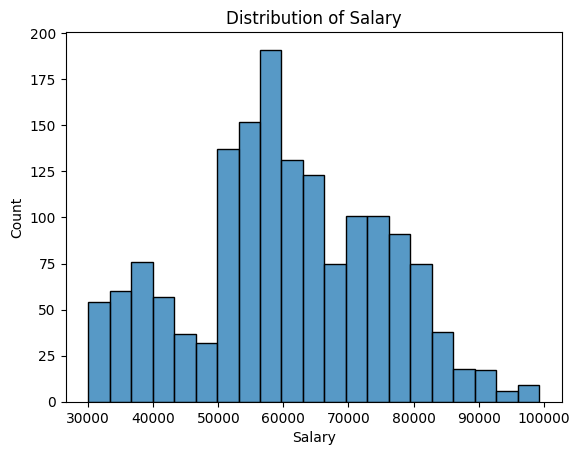

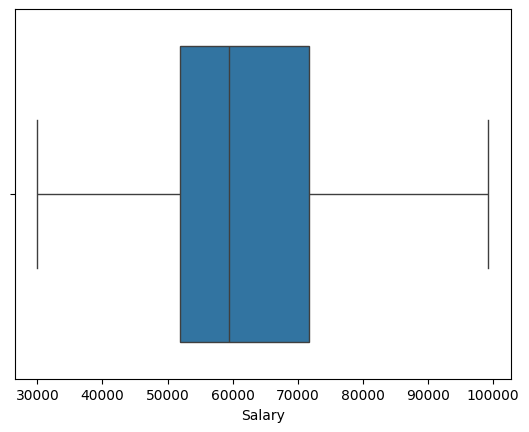

In [32]:
plt.title('Distribution of Salary')
sns.histplot(df['Salary'])
plt.show()
sns.boxplot(data=df,x='Salary')
plt.show()

<Axes: title={'center': 'Salary Distribution (20 bins)'}, xlabel='Salary', ylabel='Count'>

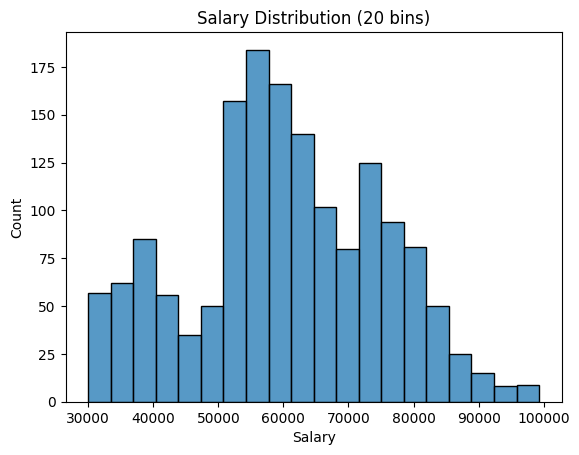

In [33]:
plt.title('Salary Distribution (20 bins)') #Customizing a Histogram by specifying Number of Bins Divides data into 20 equal-width intervals
sns.histplot(df['Salary'], bins=20)

<Axes: title={'center': 'Salary Distribution (Bin width = 5000)'}, xlabel='Salary', ylabel='Count'>

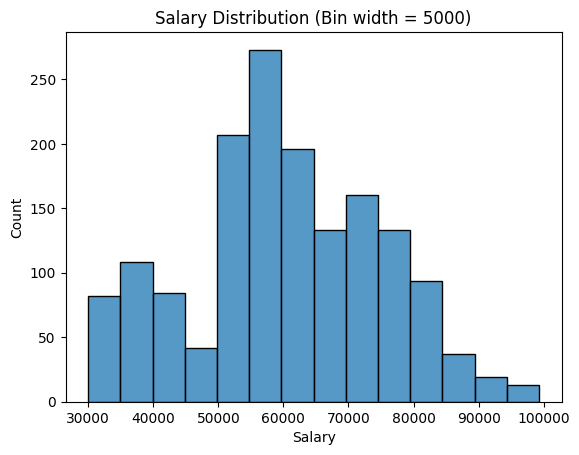

In [34]:
plt.title('Salary Distribution (Bin width = 5000)')
sns.histplot(df['Salary'], binwidth=5000) #Specifying Width of Bins

<Axes: title={'center': 'Salary Distribution with KDE'}, xlabel='Salary', ylabel='Count'>

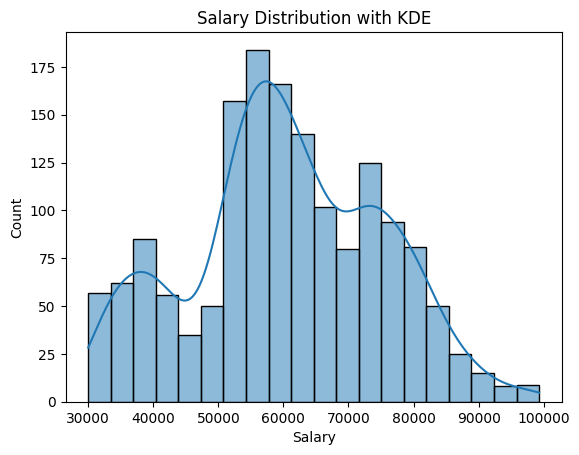

In [35]:
plt.title('Salary Distribution with KDE') #KDE = smoothed probability density curve, shows overall shape of distribution
sns.histplot(df['Salary'], bins=20, kde=True)

<Axes: title={'center': 'Salary Distribution by Gender'}, xlabel='Salary', ylabel='Count'>

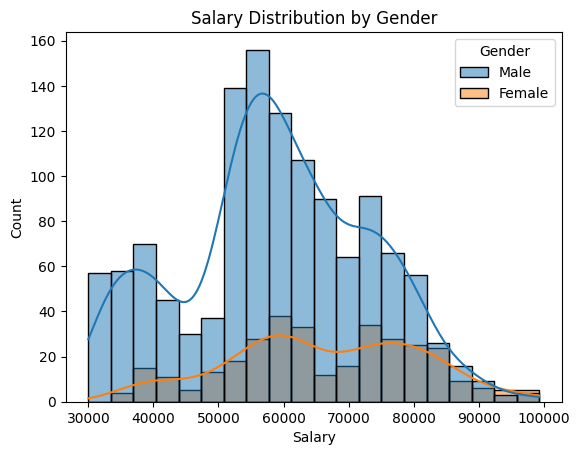

In [36]:
plt.title('Salary Distribution by Gender') #Comparing Distributions Using hue
sns.histplot(data=df, x='Salary', hue='Gender', bins=20, kde=True)

<Axes: title={'center': 'Age Distribution'}, xlabel='Age', ylabel='Count'>

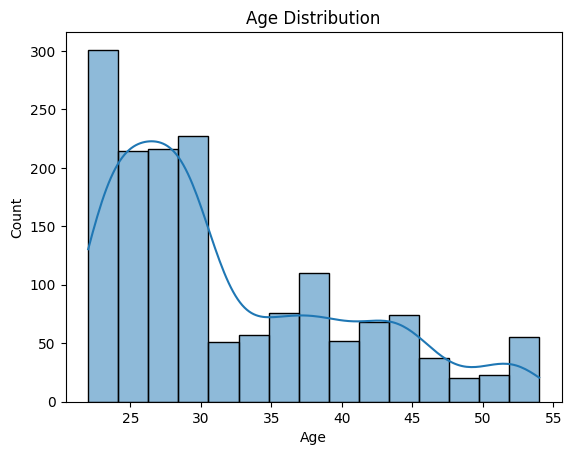

In [37]:
plt.title('Age Distribution')
sns.histplot(df['Age'], bins=15, kde=True)

Text(0.5, 1.0, 'Distribution of Car Types')

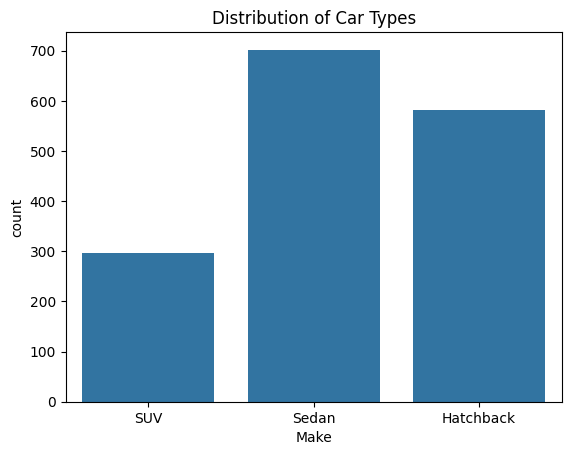

In [38]:
sns.countplot(data=df, x='Make'); # Exploring Categorical Variables for Univariate Analysys
plt.title('Distribution of Car Types')

Text(0.5, 1.0, 'Car Type Preference by Gender')

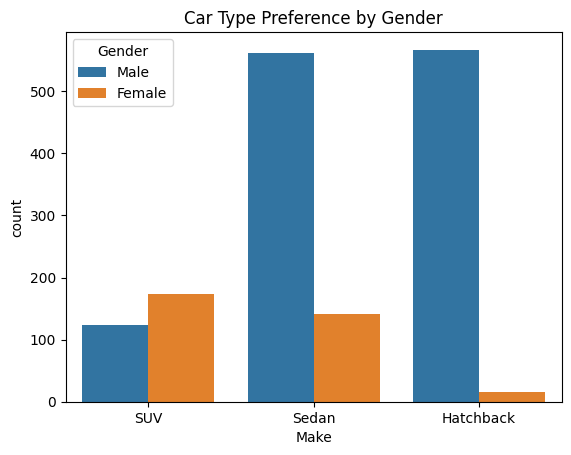

In [39]:
sns.countplot(data=df, x='Make', hue='Gender')
plt.title('Car Type Preference by Gender')

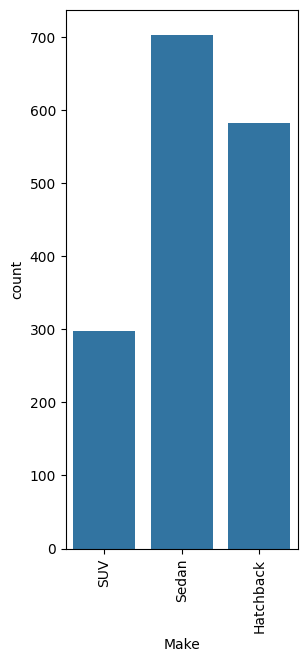

In [40]:
plt.figure(figsize=(3,7)) #Adjusting the value to increasing / decreasing the plot size
sns.countplot(data=df, x='Make');
plt.xticks(rotation=90) #rotate the tick marks to make it look better.
plt.show() # this will ensure that the plot is displayed without the text

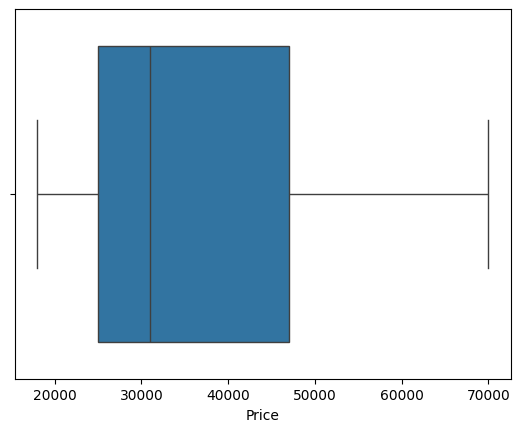

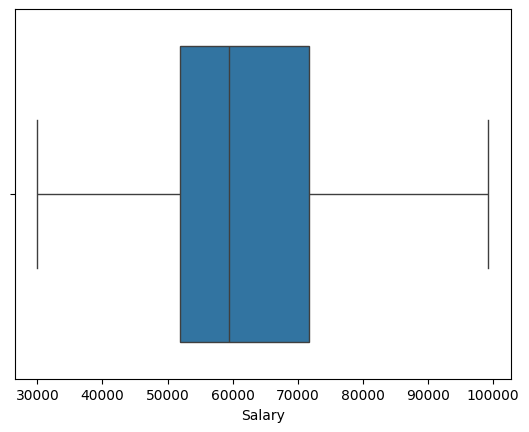

In [66]:
sns.boxplot(data=df,x='Price')
plt.show()
sns.boxplot(data=df,x='Salary')
plt.show()

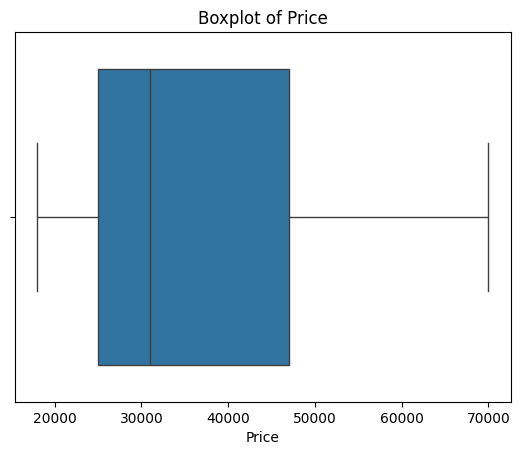

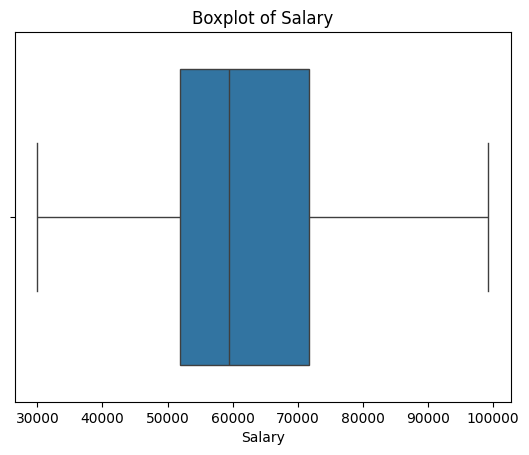

In [67]:
sns.boxplot(x=df['Price'])
plt.title('Boxplot of Price')
plt.show()
sns.boxplot(x=df['Salary'])
plt.title('Boxplot of Salary')
plt.show()

Text(0.5, 1.0, 'Price Boxplot with Custom Color')

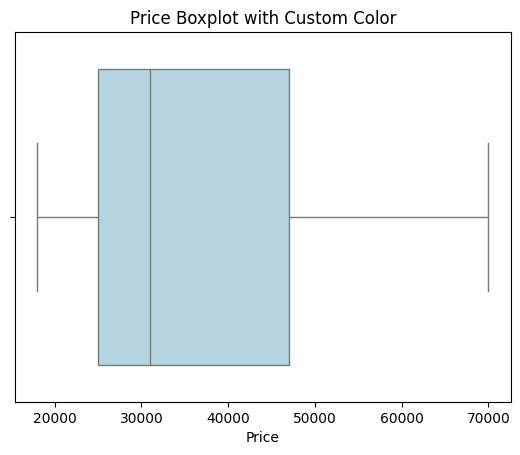

In [43]:
sns.boxplot(x=df['Price'], color='lightblue')
plt.title('Price Boxplot with Custom Color') # we can customise color

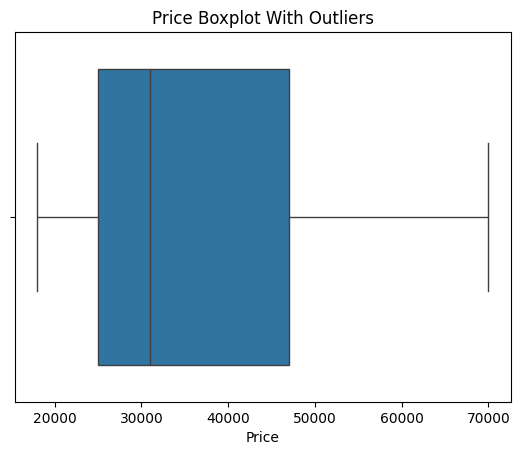

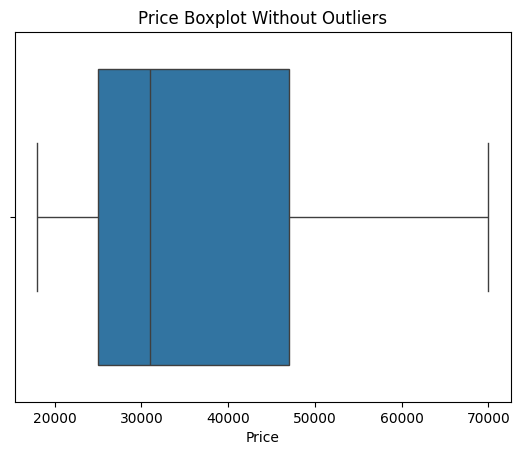

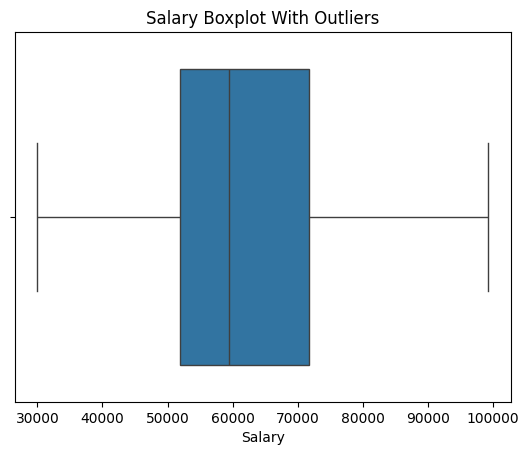

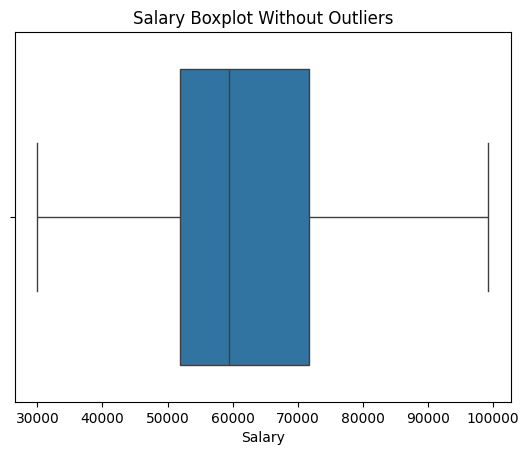

In [69]:
sns.boxplot(x=df['Price'], showfliers=True)
plt.title('Price Boxplot With Outliers') # to show or hide outliers
plt.show()
sns.boxplot(x=df['Price'], showfliers=False)
plt.title('Price Boxplot Without Outliers')
plt.show()
sns.boxplot(x=df['Salary'], showfliers=True)
plt.title('Salary Boxplot With Outliers')
plt.show()
sns.boxplot(x=df['Salary'], showfliers=False)
plt.title('Salary Boxplot Without Outliers')
plt.show()

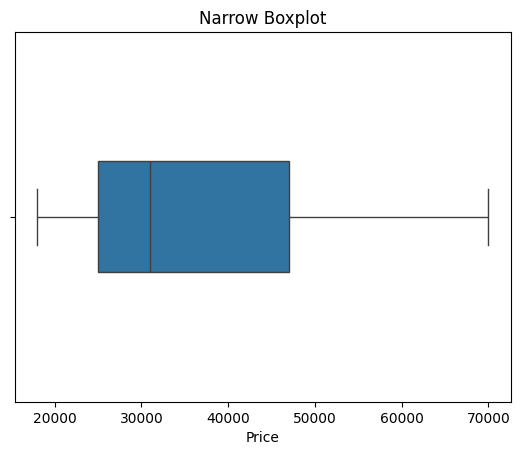

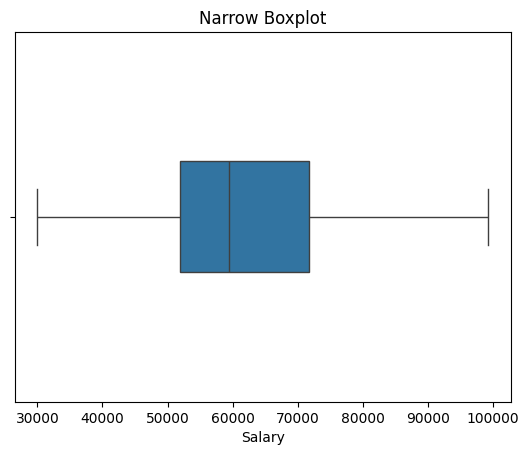

In [71]:
sns.boxplot(x=df['Price'], width=0.3)
plt.title('Narrow Boxplot') # we can customise box width
plt.show()
sns.boxplot(x=df['Salary'], width=0.3)
plt.title('Narrow Boxplot')
plt.show()

<Axes: xlabel='Price'>

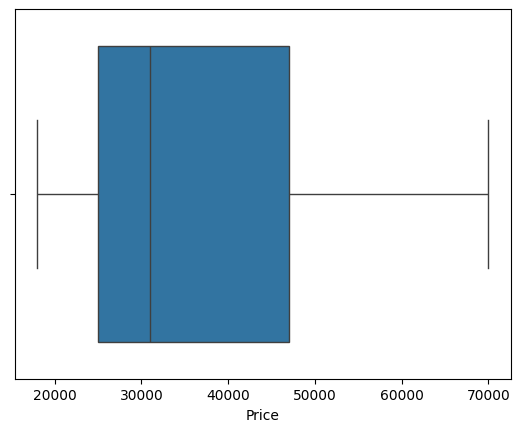

In [46]:
sns.boxplot(x=df['Price'], whis=2) # To adjust the whiskers

In [72]:
Q1 = df['Price'].quantile(0.25)
Q3 = df['Price'].quantile(0.75)
IQR = Q3 - Q1
Q1 = df['Salary'].quantile(0.25)
Q3 = df['Salary'].quantile(0.75)
IQR = Q3 - Q1

In [73]:
lower_whisker = Q1 - 1.5 * IQR
upper_whisker = Q3 + 1.5 * IQR

outliers_price = df[(df['Price'] < lower_whisker) | (df['Price'] > upper_whisker)]
outliers_salary = df[(df['Salary'] < lower_whisker) | (df['Salary'] > upper_whisker)]

In [75]:
df['Price_capped'] = df['Price'].clip(lower=lower_bound, upper=upper_bound)

<Axes: xlabel='Price_capped'>

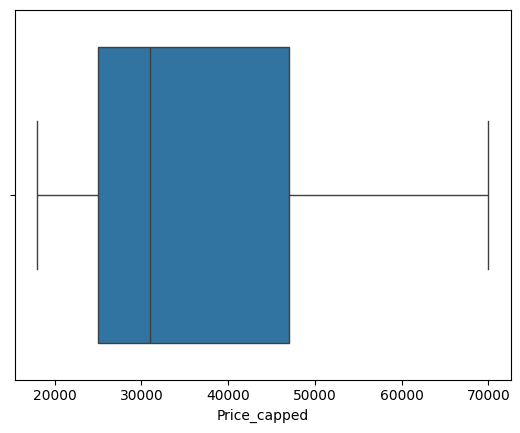

In [76]:
sns.boxplot(x=df['Price_capped'])

<Figure size 600x400 with 0 Axes>

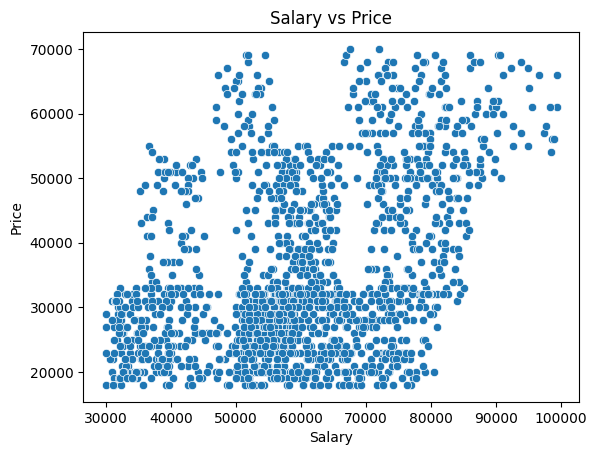

<Figure size 600x400 with 0 Axes>

In [50]:
plt.title('Salary vs Price') # To find the relationship between two continuous variables
sns.scatterplot(x='Salary', y='Price', data=df)
plt.figure(figsize=(6,4))

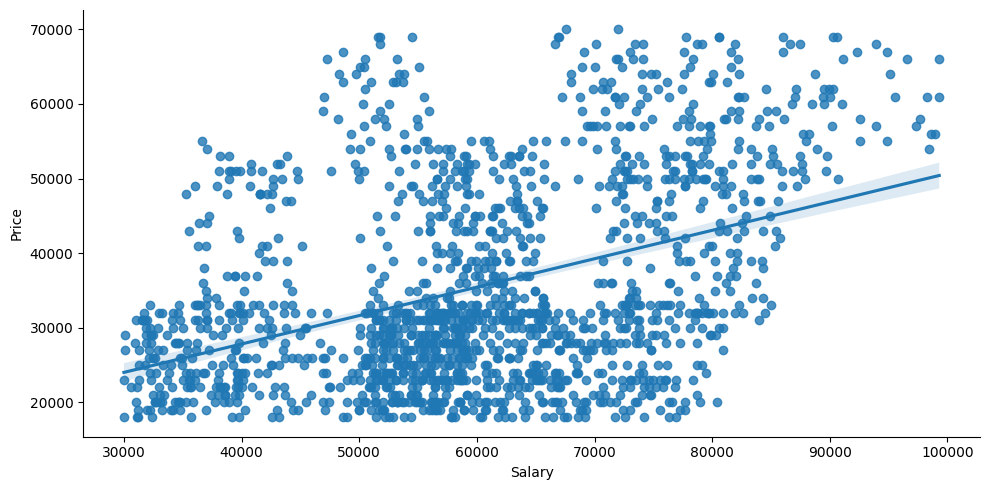

In [51]:
sns.lmplot(data=df, x='Salary', y='Price', height=5, aspect=2) # To check the regression line slope

In [52]:
df[['Salary','Price']].corr() # lets check the correlation between Salary and Price

,Salary,Price
Salary,1.000,0.410
Price,0.410,1.000


<Figure size 800x600 with 0 Axes>

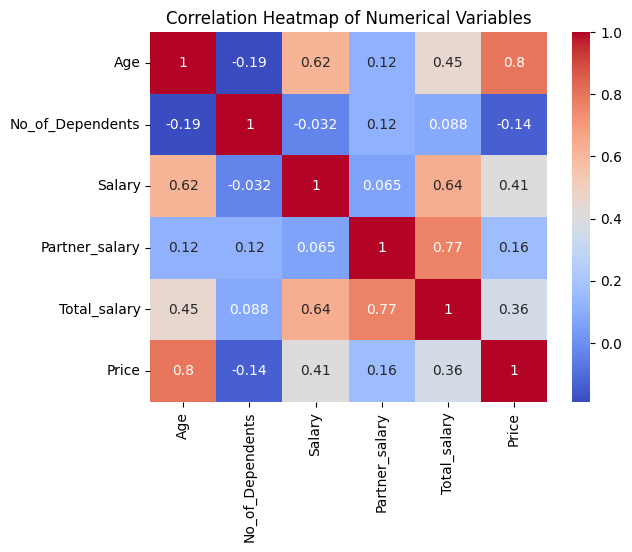

<Figure size 800x600 with 0 Axes>

In [53]:
corr_matrix = df.corr(numeric_only=True) # To get visual output for correlation with heatmap
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap of Numerical Variables')
plt.figure(figsize=(8,6))

/tmp/ipython-input-1958159522.py:1: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.lineplot(data=df, x='Make', y ='Price',ci=None) # To check the price range with the make of car to conclude on the buying aspect


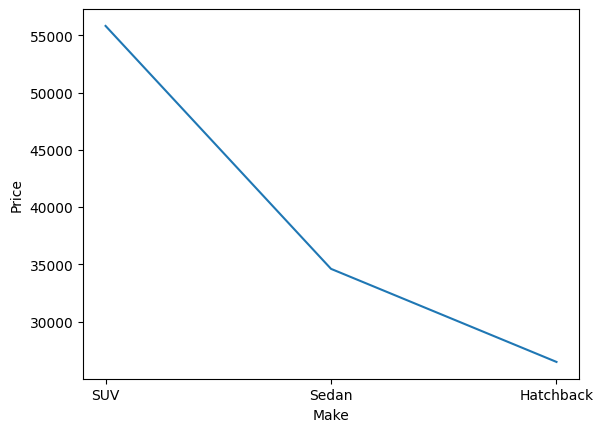

<Figure size 1500x700 with 0 Axes>

In [54]:
sns.lineplot(data=df, x='Make', y ='Price',ci=None) # To check the price range with the make of car to conclude on the buying aspect
plt.figure(figsize=(15,7))
plt.show()

In [55]:
price_bins = [0, 20000, 40000, 60000, 100000] # to convert a numerical variable into groups and then analyze its relationship with another numerical variable.
price_labels = ['Low', 'Medium', 'High', 'Premium']
df['Price_Category'] = pd.cut(df['Price'],bins=price_bins,labels=price_labels)
df['Price_Category'].value_counts()

,count
Price_Category,
Medium,912
High,401
Low,161
Premium,107


In [56]:
df.groupby('Price_Category')['Total_salary'].mean() # to analyse relationship

/tmp/ipython-input-2307496979.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('Price_Category')['Total_salary'].mean() # to analyse relationship


,Total_salary
Price_Category,
Low,68436.646
Medium,75175.987
High,87993.017
Premium,99673.832


Text(0.5, 1.0, 'Average Total Salary by Car Price Category')

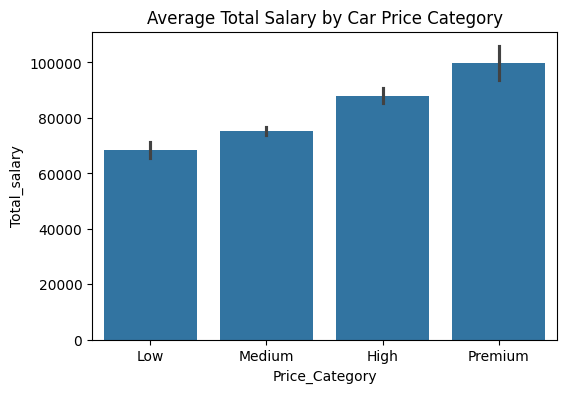

In [57]:
plt.figure(figsize=(6,4))
sns.barplot(x='Price_Category', y='Total_salary', data=df)
plt.title('Average Total Salary by Car Price Category')

Text(0.5, 1.0, 'Average Car Price by Gender')

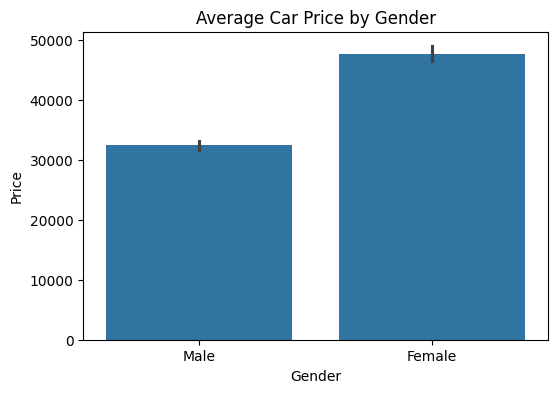

In [58]:
plt.figure(figsize=(6,4)) # To Compare average numerical value across categories
sns.barplot(x='Gender', y='Price', data=df)
plt.title('Average Car Price by Gender')

In [59]:
df.groupby('Make')['Price'].agg(['mean','median','count']) #Grouped statistical summary for the purpose to support plots with numbers

,mean,median,count
Make,,,
Hatchback,26474.227,27000.000,582
SUV,55824.916,57000.000,297
Sedan,34603.989,33000.000,702


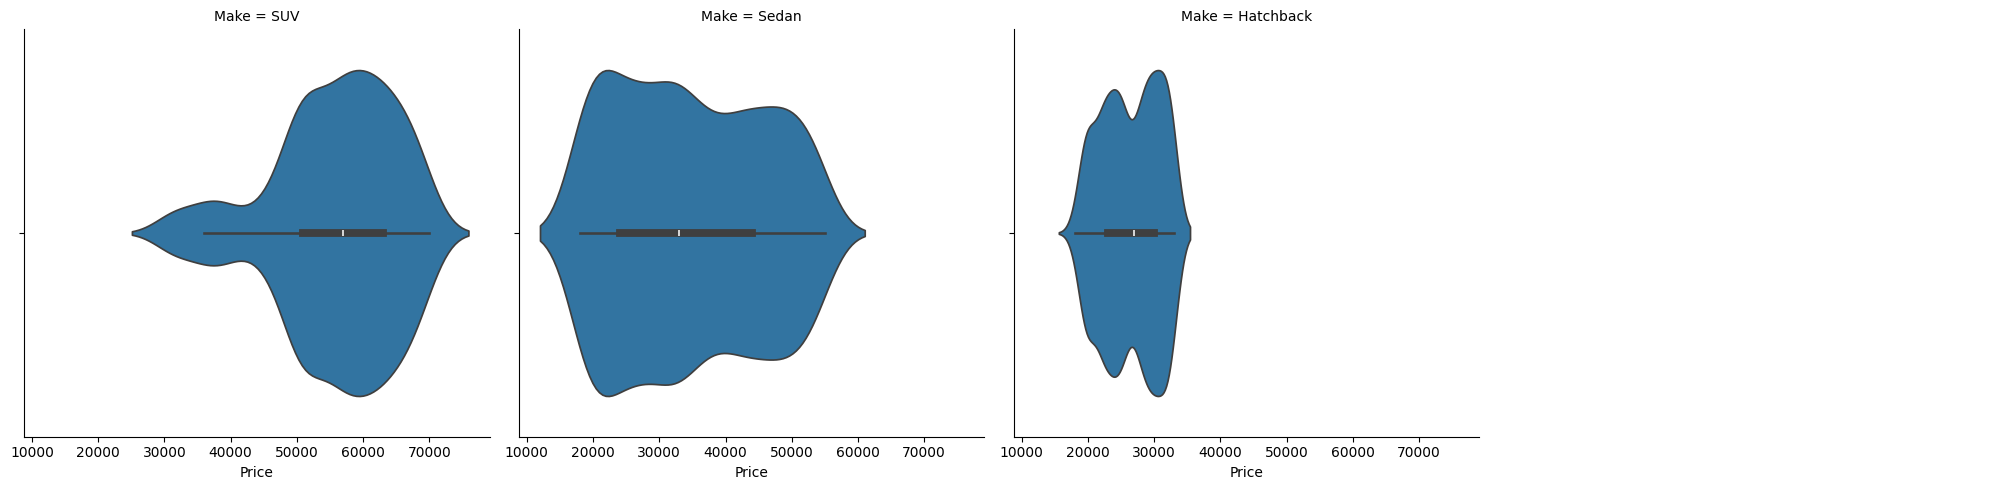

In [60]:
sns.catplot(x='Price',col='Make',data=df,col_wrap=4,kind="violin") #A violin plot shows the distribution of quantitative data across different categories
plt.show()

Text(0.5, 1.0, 'Car Price Distribution by Gender')

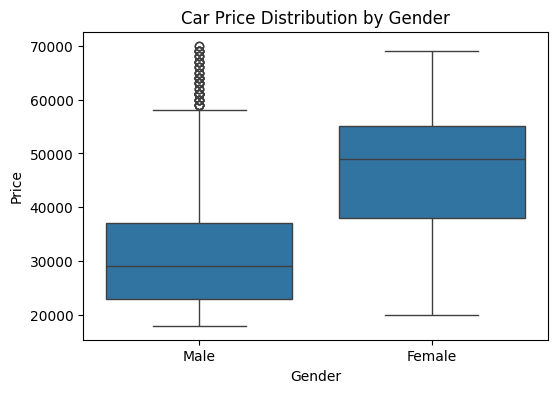

In [61]:
plt.figure(figsize=(6,4)) # To compare distribution, median, spread, and outliers
sns.boxplot(x='Gender', y='Price', data=df)
plt.title('Car Price Distribution by Gender')

#####Several dots above the upper whisker → clear outliers,Right-skewed distribution:

Most customers buy mid-range cars

A few customers spend significantly more


In [62]:
Q1 = df['Price'].quantile(0.25) # we check for the outliers
Q3 = df['Price'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [63]:
outliers = df[(df['Price'] < lower_bound) | (df['Price'] > upper_bound)] # To check how many outliers exists

In [64]:
df['Price_capped'] = df['Price'].clip(lower=lower_bound, upper=upper_bound)

#####In the above IQR-based lower and upper whiskers, effectively bringing extreme outliers closer to the rest of the data.

<Axes: xlabel='Price_capped'>

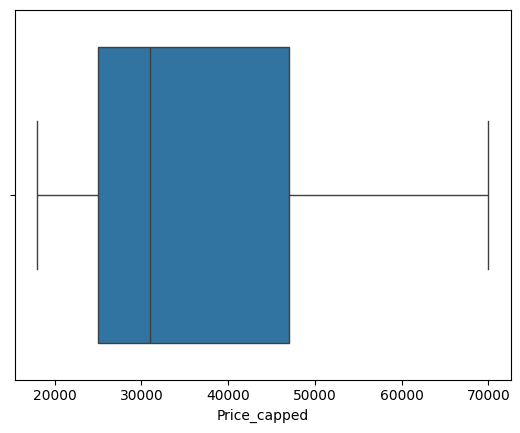

In [65]:
sns.boxplot(x=df['Price_capped']) # To recheck after removing outliers